# Setup

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gridforecast.config import UK
from gridforecast.data import weather
from gridforecast.data.calendar import bank_holidays
from gridforecast.data.clean import build_model_table, gap_report
from gridforecast.data.store import load
from gridforecast.pipeline.ingest import DEMAND, weather_path

plt.rcParams["figure.figsize"] = (11, 4.5)

# Build the Clean Table

In [2]:
nat = weather.national_weather(load(weather_path("historical_forecast")))
table = build_model_table(load(DEMAND), nat)
table = table.loc[: table["indo_mw"].last_valid_index()]  # drop rows that only have weather
local = table.index.tz_convert(UK)
print(table.shape)
table.describe().T.round(1)

(102513, 8)


,count,mean,std,min,25%,50%,75%,max
indo_mw,102273.0,26462.0,6066.9,12621.0,21756.0,25582.0,30219.0,47319.0
temperature_2m,102513.0,11.9,5.9,-6.5,7.6,11.6,16.0,36.2
apparent_temperature,102513.0,9.5,7.0,-11.5,4.3,9.1,14.5,35.3
shortwave_radiation,102513.0,110.7,172.0,0.0,0.0,6.4,170.5,873.2
cloud_cover,102513.0,72.1,26.3,0.0,56.1,80.3,94.4,100.0
wind_speed_10m,102513.0,3.5,1.5,0.6,2.4,3.3,4.3,13.4
precipitation,102513.0,0.1,0.2,0.0,0.0,0.0,0.1,5.0


# Where are the gaps?

In [3]:
gaps = gap_report(table["indo_mw"])
print(f"{len(gaps)} gaps, {gaps['periods'].sum()} missing half-hours in total")
gaps.sort_values("periods", ascending=False).head(10)

3 gaps, 240 missing half-hours in total


,start,periods
0,2021-02-15 23:30:00+00:00,96
2,2021-03-09 23:30:00+00:00,96
1,2021-02-25 23:30:00+00:00,48


# daily shape, weekday vs weekend, winter vs summer.
 - Expecting a winter evening peak around 17:00–18:00 UK time.

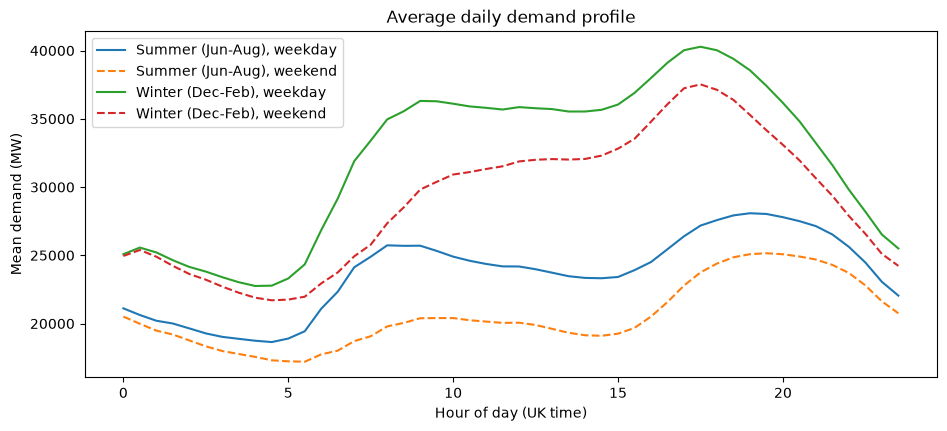

In [4]:
season = np.select(
    [local.month.isin([12, 1, 2]), local.month.isin([6, 7, 8])],
    ["Winter (Dec-Feb)", "Summer (Jun-Aug)"],
    "Other",
)
df = table.assign(
    hour=local.hour + local.minute / 60, weekend=local.day_of_week >= 5, season=season
)
fig, ax = plt.subplots()
for (s, weekend), g in df[df["season"] != "Other"].groupby(["season", "weekend"]):
    profile = g.groupby("hour")["indo_mw"].mean()
    ax.plot(
        profile.index,
        profile.values,
        ls="--" if weekend else "-",
        label=f"{s}, {'weekend' if weekend else 'weekday'}",
    )
ax.set(
    xlabel="Hour of day (UK time)", ylabel="Mean demand (MW)", title="Average daily demand profile"
)
ax.legend()

# temperature response, one dot per day.
- It should look like a hockey stick: flat when warm, rising as it gets colder.

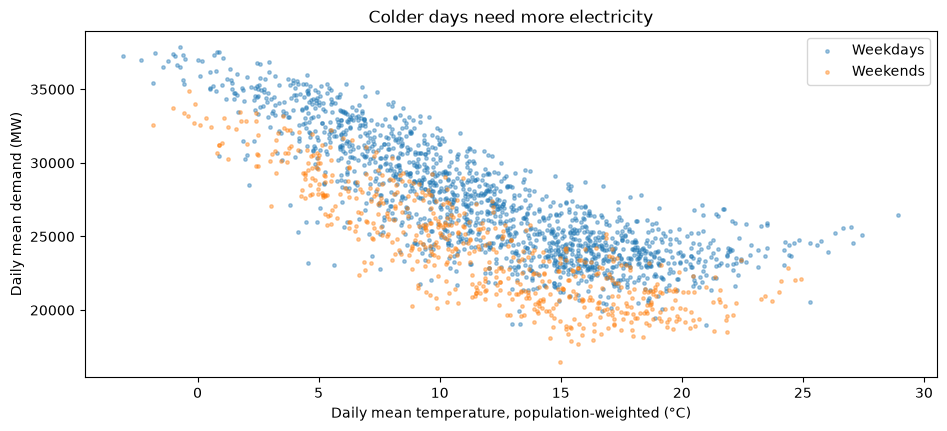

In [5]:
daily = table.groupby(local.date).agg(demand=("indo_mw", "mean"), temp=("temperature_2m", "mean"))
weekday = pd.to_datetime(daily.index).day_of_week < 5
fig, ax = plt.subplots()
ax.scatter(
    daily.loc[weekday, "temp"], daily.loc[weekday, "demand"], s=6, alpha=0.4, label="Weekdays"
)
ax.scatter(
    daily.loc[~weekday, "temp"], daily.loc[~weekday, "demand"], s=6, alpha=0.4, label="Weekends"
)
ax.set(
    xlabel="Daily mean temperature, population-weighted (°C)",
    ylabel="Daily mean demand (MW)",
    title="Colder days need more electricity",
)
ax.legend()

# the solar dip.
- INDO is metered on the transmission network, so rooftop and other embedded solar is invisible and reduces measured demand on sunny days.
- This is why radiation is a demand feature, not just a generation one.

[Text(0.5, 0, 'Solar radiation (W/m²)'),
 Text(0, 0.5, 'Demand (MW)'),
 Text(0.5, 1.0, 'Sunny middays lower measured demand (rooftop solar is invisible to INDO)')]

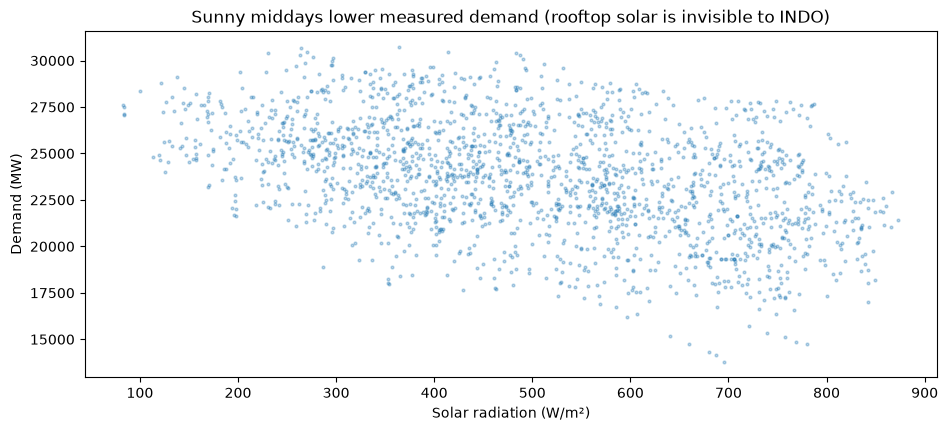

In [6]:
midday = df[(df["season"] == "Summer (Jun-Aug)") & ~df["weekend"] & df["hour"].between(12, 14)]
fig, ax = plt.subplots()
ax.scatter(midday["shortwave_radiation"], midday["indo_mw"], s=4, alpha=0.3)
ax.set(
    xlabel="Solar radiation (W/m²)",
    ylabel="Demand (MW)",
    title="Sunny middays lower measured demand (rooftop solar is invisible to INDO)",
)

# long-term trend.
- Transmission demand drifts down over the years (efficiency, embedded generation, the 2022 price shock), which is why a model trained once will slowly go stale.

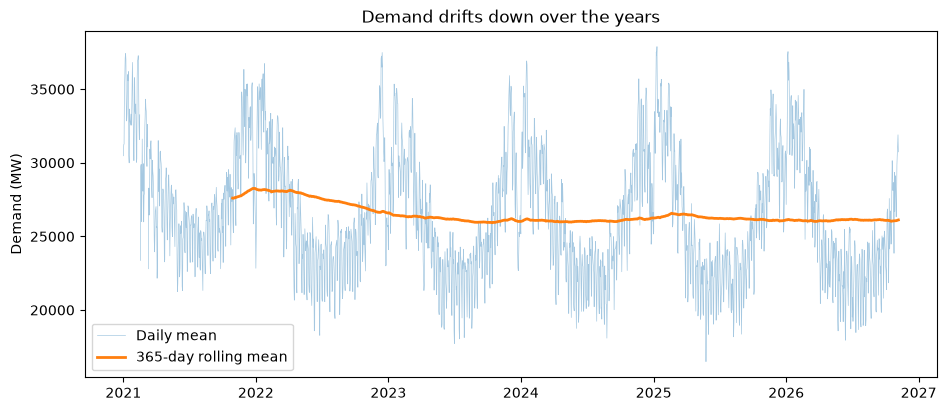

In [7]:
fig, ax = plt.subplots()
daily_mean = table["indo_mw"].resample("D").mean()
ax.plot(daily_mean.index, daily_mean, lw=0.5, alpha=0.4, label="Daily mean")
ax.plot(
    daily_mean.index,
    daily_mean.rolling(365, min_periods=300).mean(),
    lw=2,
    label="365-day rolling mean",
)
ax.set(ylabel="Demand (MW)", title="Demand drifts down over the years")
ax.legend()

# bank holidays vs normal days.
- Each holiday is compared with the same weekday one and two weeks either side.

In [8]:
hols = bank_holidays(range(local.year.min(), local.year.max() + 1))
by_day = table["indo_mw"].groupby(local.date).mean()
rows = []
for h in sorted(hols):
    if h not in by_day.index:
        continue
    same_weekday = [h + timedelta(days=d) for d in (-14, -7, 7, 14)]
    rows.append(
        {"date": h, "holiday_mw": by_day[h], "normal_mw": by_day.reindex(same_weekday).mean()}
    )
holiday_effect = pd.DataFrame(rows)
holiday_effect["change_pct"] = 100 * (
    holiday_effect["holiday_mw"] / holiday_effect["normal_mw"] - 1
)
holiday_effect.round(1).tail(12)

,date,holiday_mw,normal_mw,change_pct
42,2025-04-21,23776.1,23486.6,1.2
43,2025-05-05,21765.8,23130.5,-5.9
44,2025-05-26,19029.5,22598.6,-15.8
45,2025-08-25,18964.4,23135.5,-18.0
46,2025-12-25,25292.5,31581.9,-19.9
47,2025-12-26,25976.4,31950.8,-18.7
48,2026-01-01,27166.7,32106.1,-15.4
49,2026-04-03,23689.8,26243.8,-9.7
50,2026-04-06,22022.2,26506.7,-16.9
51,2026-05-04,23342.3,24645.6,-5.3


# autocorrelation.
- Spikes at 1, 7 and 14 days

[Text(0.5, 0, 'Lag (days)'),
 Text(0, 0.5, 'Autocorrelation'),
 Text(0.5, 1.0, 'Demand repeats daily and weekly')]

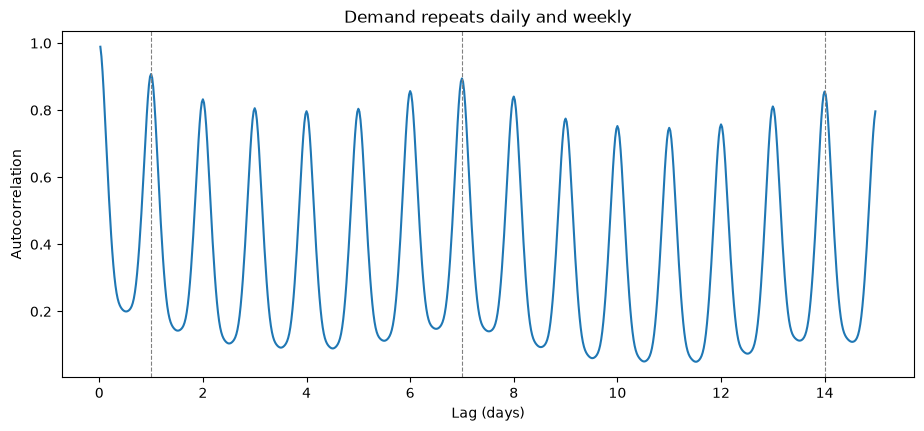

In [9]:
s = table["indo_mw"]
lags = np.arange(1, 48 * 15)
acf = [s.autocorr(int(lag)) for lag in lags]
fig, ax = plt.subplots()
ax.plot(lags / 48, acf)
for d in (1, 7, 14):
    ax.axvline(d, color="grey", ls="--", lw=0.8)
ax.set(xlabel="Lag (days)", ylabel="Autocorrelation", title="Demand repeats daily and weekly")